# AgroPest-12 Part B: I-JEPA Pretraining for YOLOv12m

**Model:** YOLOv12m backbone, strict label-free I-JEPA pretraining  
**Dataset:** AgroPest-12-PartB-Safe SSL pool (9,180 images)  
**Platform:** Kaggle T4 x2  

This notebook pretrains a randomly initialized YOLOv12m backbone with an I-JEPA-style latent prediction objective. It reads only `ssl_pool/images`; labels, validation images, and test images are never accessed.

## Method and Protocol

I-JEPA (Image-based Joint-Embedding Predictive Architecture) predicts latent representations of masked target regions from a visible context. A target encoder produces the complete spatial feature map. Several rectangular blocks are sampled on that map as prediction targets. Their corresponding image regions are masked from the context encoder's input. A lightweight transformer predictor then predicts the target latents from the context features.

The loss is smooth L1 regression in latent space: \( L = \text{SmoothL1}(p, \operatorname{sg}(z)) \), where \( p \) is the predicted target representation, \( z \) is the target encoder's output, and \( \operatorname{sg} \) stops gradients. The target encoder is updated via EMA: \( \xi \leftarrow m\xi + (1-m)\theta \).

I-JEPA replaces hand-crafted colour augmentations with spatial masking as the invariance signal. No contrastive negatives are needed. Only the online encoder transfers to the downstream detector.

The Part B partition policy forbids reading labels, validation images, or test images in this notebook. Diagnostics therefore use a fixed image-only sample from the SSL pool and do not make label-based claims.

In [1]:
# Install the current course SSL library and visualization dependency.
import subprocess, sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "ultralytics>=8.4.96", "scikit-learn", "seaborn"])
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "--no-deps", "git+https://github.com/rifat963/ssl-detection-lab.git@main"])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 89.6 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sklearn-compat 0.1.5 requires scikit-learn<1.9,>=1.2, but you have scikit-learn 1.9.0 which is incompatible.


0

In [2]:
# ============================================================
# CONFIG -- every value is fixed and viva-explainable
# ============================================================
from pathlib import Path

PARTB_ROOT = Path("/kaggle/input/datasets/sadikshahriar/agropest-12-partb-safe/AgroPest-12-PartB-Safe")
SSL_IMAGES = PARTB_ROOT / "ssl_pool" / "images"
OUTPUT_DIR = Path("/kaggle/working/partB_03a_ijepa_yolo12m")

SEED = 445                 # Shared Part B seed and fixed diagnostic sample.
YOLO_MODEL = "yolo12m.yaml" # Random architecture: no COCO-supervised initialization.
EPOCHS = 30                # Assignment B standard SSL pretraining budget.
IMAGE_SIZE = 224           # 88.9% of AgroPest boxes are large; preserves morphology. The 7x7 grid at 224px (stride 32) matches YOLOv12m's P3 spatial scale.
PER_GPU_BATCH = 128        # Validated by warm-up run: ~8 GiB/15 GB T4 at 224px. I-JEPA does online+target passes but the transformer predictor operates on a 7x7 grid (lightweight).
WORKERS = 2                # Matches the Part A two-workers-per-GPU data-loading budget.
LEARNING_RATE = 3e-4       # Conservative AdamW rate inherited from the validated SimCLR/BYOL AgroPest protocols.
MIN_LEARNING_RATE = 3e-6   # 100x lower cosine-decay floor for this 30-epoch SSL run.
WEIGHT_DECAY = 1e-4        # SSL regularization for the random encoder, projector, and predictor.
WARMUP_EPOCHS = 2          # Extended warmup: I-JEPA suffers more from early instability because the target encoder must produce meaningful latents before the predictor can learn (Assran et al. Fig 7: faster convergence needs stable early targets).
# --- I-JEPA latent prediction parameters ---
PROJECTION_DIM = 256       # Paper Table 14: bottleneck width 384 is optimal; 256 is the library default for full runs. Retained because YOLOv12m's smaller feature dimension makes 256 a comparable bottleneck ratio.
HIDDEN_DIM = 512           # Matches YOLOv12m pooled-feature scale; the projector expands to this before the predictor.
MASK_RATIO = 0.60          # Required by config validation. I-JEPA masking is actually controlled by num_target_blocks * target_scale; this field is unused by the I-JEPA module.
NUM_TARGET_BLOCKS = 4      # Paper Table 10: 4 blocks optimal (54.2%) vs 3 (48.5%) vs 2 (22.0%). Strictly monotonic; stopped at 4. More targets = more SSL signal per image, critical at 30 epochs.
TARGET_SCALE_MIN = 0.10    # Paper Table 8: scale (0.15-0.2) peaks at 54.2%; (0.1-0.2) gets 39.2%. We widen slightly to 0.10-0.25 because AgroPest boxes are 88.9% large, so targets covering more of the 7x7 grid still capture semantic pest regions.
TARGET_SCALE_MAX = 0.25    # Upper bound 0.25 is safe: paper shows (0.2-0.25) achieves 38.9%, sharper drop at (0.2-0.3) = 33.6%. Above 0.30 degrades because context becomes too impoverished.
TARGET_ASPECT_MIN = 0.75   # Nearly square blocks; pests (ants, beetles, caterpillars, moths) are roughly isotropic. Paper does not ablate this explicitly; kept at the canonical value.
TARGET_ASPECT_MAX = 1.50
PREDICTOR_DEPTH = 2        # Paper Table 12: deeper predictors help (depth 12 > 6) but require longer training. At 30 epochs on a CNN backbone, depth=2 avoids underfitting while converging in the limited budget.
PREDICTOR_HEADS = 4        # Standard for projection_dim=256; satisfies config validator (256 % 4 == 0).
# --- EMA target encoder ---
MOMENTUM = 0.996           # Canonical I-JEPA EMA momentum (Assran et al., CVPR 2023). Unlike BYOL, I-JEPA's masking + target blocking provides additional anti-collapse structure, so the longer 1000-epoch schedule value is appropriate even at 30 epochs.
FINAL_MOMENTUM = 1.0       # Cosine schedule: tau=1-(1-tau_base)*(cos(pi*k/K)+1)/2.
DIAGNOSTIC_IMAGES = 500    # Fixed image-only SSL-pool sample for t-SNE/retrieval.
RETRIEVAL_QUERIES = 4      # Four random panels, matching the SimCLR sanity-check style.
RETRIEVAL_NEIGHBORS = 5    # Assignment B requires query plus top-five cosine neighbours.

CLASS_NAMES = ["Ants", "Bees", "Beetles", "Caterpillars", "Earthworms", "Earwigs", "Grasshoppers", "Moths", "Slugs", "Snails", "Wasps", "Weevils"]
print(f"CONFIG loaded | I-JEPA | {YOLO_MODEL} | {EPOCHS} epochs | {PER_GPU_BATCH} images/GPU | {IMAGE_SIZE}px | {NUM_TARGET_BLOCKS} target blocks | mask {MASK_RATIO}")

CONFIG loaded | I-JEPA | yolo12m.yaml | 30 epochs | 128 images/GPU | 224px | 4 target blocks | mask 0.6


## Dataset-Specific CONFIG Rationale

Every I-JEPA parameter below is cross-referenced against Assran et al. (CVPR 2023) ablation tables. The key departures from the paper defaults are motivated by the 30-epoch budget and AgroPest's 88.9% large-box distribution.

**Resolution (224px) and grid:** At stride 32, the YOLOv12m backbone produces a 7x7 spatial feature grid. Target blocks are sampled on this grid, not on pixels. Each cell covers a 32x32-pixel image patch. The target scale range 0.10-0.25 means blocks span ~0.7-1.75 grid cells per side, which in image space covers ~22-56 px. For AgroPest's large pests, these blocks frequently contain complete insect bodies - a favourable property for learning pest-level semantics.

**No colour augmentations:** I-JEPA's `build_transform` returns only random resized crop (0.50-1.0 scale), horizontal flip, and ImageNet normalization. No colour jitter, grayscale, or Gaussian blur. Spatial masking replaces hand-crafted augmentations as the invariance mechanism: the predictor must infer the appearance of hidden regions from surrounding visible context, which is a stronger spatial-semantic training signal than pixel-level colour perturbations. This is well-suited to agriculture where pest colour (e.g., green caterpillar on green leaf) is often non-discriminative — spatial structure matters more.

**EMA momentum (0.996):** Unlike BYOL where we lowered to 0.99 for short training, I-JEPA retains the canonical 0.996. The multi-block masking mechanism provides an independent inductive bias against collapse (the context encoder is forced to produce features informative about diverse spatial locations), so the EMA does not carry the full anti-collapse burden. The Assran et al. training used 0.996 at all scales.

**Batch size (128/GPU):** Empirically validated at ~8 GiB/15 GB T4. I-JEPA runs online context encoder, target encoder (no-grad, EMA), and a lightweight transformer predictor on 7x7 spatial grids. The predictor overhead is minimal (49 tokens x 256-dim).

**Target blocks (4 blocks, scale 0.10-0.25):** Paper Table 10 shows 4 blocks strictly dominates fewer (54.2% vs 48.5% for 3, vs 22.0% for 2). The scale range is widened from the paper's optimal (0.15-0.20) to (0.10-0.25) because AgroPest's 88.9% large boxes mean targets at even the upper bound still capture meaningful pest regions. Paper Table 8 shows (0.10-0.20) at 39.2% and (0.20-0.25) at 38.9% — both acceptable ranges that bracket the optimal peak.

**Predictor (depth 2, 4 heads, 256-dim):** Paper Table 12 shows deeper predictors improve (depth 12 > 6) but require long training. At 30 epochs on a CNN backbone, depth=2 balances capacity with convergence speed. Projection dim 256 follows the paper's bottleneck-width principle (Table 14: 384-dim is optimal for ViT; 256 is proportionally scaled to YOLOv12m's smaller encoder output).

**Extended warmup (2 epochs):** I-JEPA has a cold-start problem: the target encoder must produce meaningful representations before the predictor has a useful training signal. Two warmup epochs let the EMA accumulate a stable initial target before the learning rate peaks, reducing early-train loss oscillation (Assran et al. Fig. 7 shows rapid initial convergence depends on target quality).

In [3]:
# ============================================================
# Environment and strict SSL-pool-only checks
# ============================================================
import json, random
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2
from tqdm.auto import tqdm
from ultralytics import YOLO

import ssldet
from ssldet import PretrainConfig, assert_supported_runtime, available_ssl_modules, launch_distributed_pretrain, transfer_ssl_backbone_to_yolo
from ssldet.backbones import YOLOBackboneEncoder
from ssldet.data import IMAGENET_MEAN, IMAGENET_STD, UnlabeledImageDataset, build_transform
from ssldet.ssl import sample_target_blocks

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.set_float32_matmul_precision("high")
sns.set_theme(style="whitegrid")

assert SSL_IMAGES.is_dir(), f"Attach AgroPest-12-PartB-Safe. Missing: {SSL_IMAGES}"
assert not any(SSL_IMAGES.parent.rglob("*.txt")), "SSL pool must not contain label files."
runtime = assert_supported_runtime(require_cuda=True, minimum_gpus=2)
assert "ijepa" in available_ssl_modules()

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png"}
ssl_paths = sorted(path for path in SSL_IMAGES.iterdir() if path.suffix.lower() in IMAGE_SUFFIXES)
assert len(ssl_paths) == 9180, f"Expected 9,180 SSL images, found {len(ssl_paths)}"

pd.Series({
    "ssl-detection-lab": ssldet.__version__, "PyTorch": torch.__version__,
    "Ultralytics": runtime["packages"]["ultralytics"]["installed"],
    "GPU count": runtime["cuda"]["device_count"],
    "GPUs": ", ".join(device["name"] for device in runtime["cuda"]["devices"]),
    "SSL images": len(ssl_paths), "label files visible": 0,
})

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


ssl-detection-lab                   0.8.0
PyTorch                      2.10.0+cu128
Ultralytics                       8.4.105
GPU count                               2
GPUs                   Tesla T4, Tesla T4
SSL images                           9180
label files visible                     0
dtype: object

## Augmentation and Target Block Preview

I-JEPA uses a single-view transform (random resized crop + horizontal flip + normalize, no colour augmentations). During training, the sampled target block regions are masked from the context encoder's input while the target encoder sees the full image. The masks below show the latent-grid target blocks that the context encoder must predict.

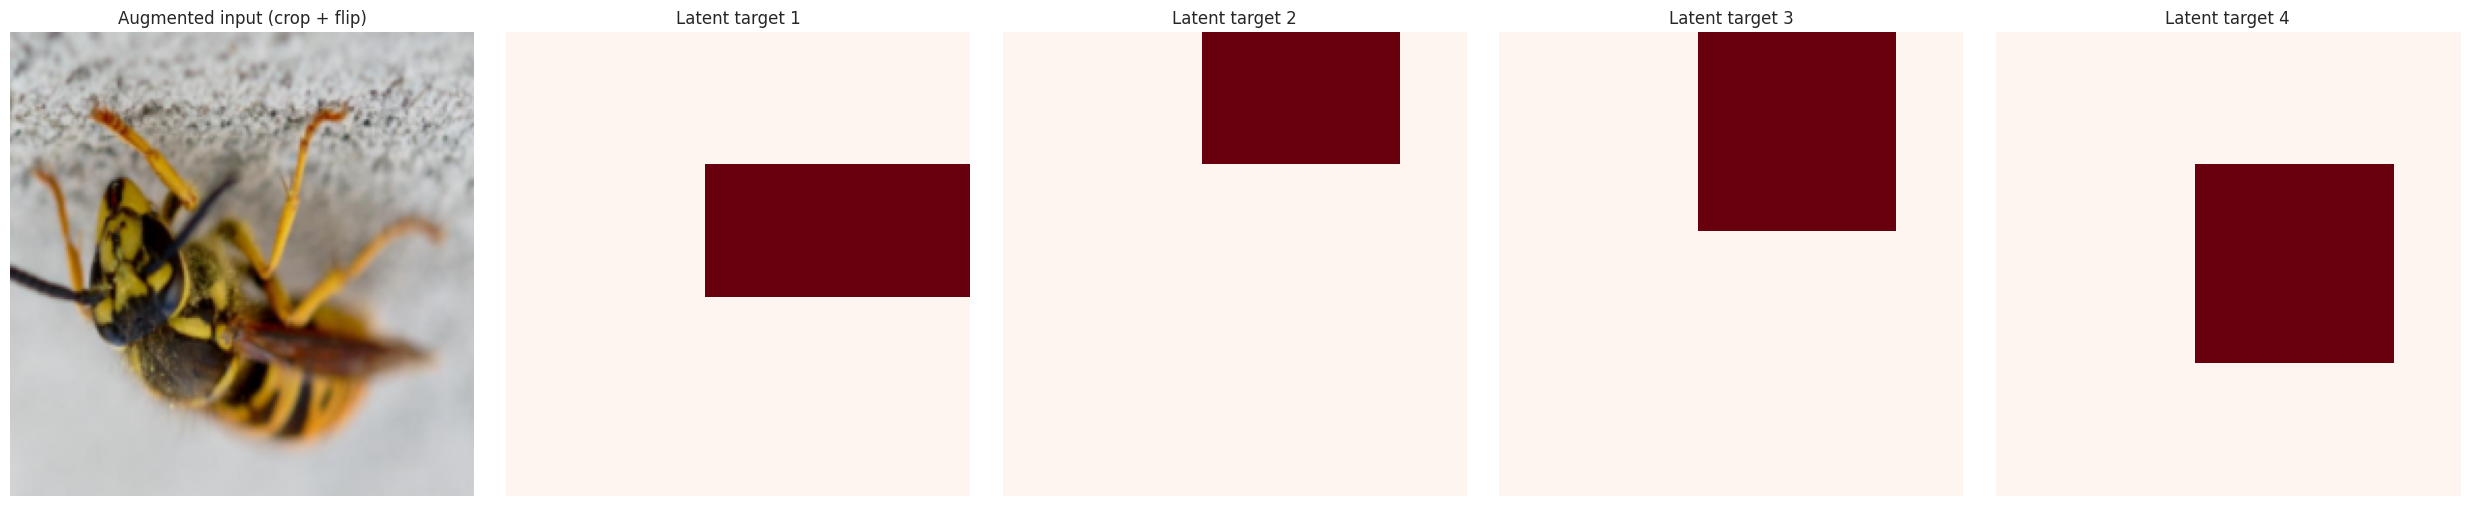

model initialization          random yolo12m.yaml (strict label-free SSL)
source images per DDP step                                            256
spatial grid                                     7x7 (stride 32 at 224px)
target blocks per image                                                 4
target scale range                                               0.1-0.25
mask ratio                                                            0.6
EMA momentum                                                        0.996
AMP                                                                  True
dtype: object

In [4]:
config = PretrainConfig(
    method="ijepa", image_roots=[str(SSL_IMAGES)], output_dir=str(OUTPUT_DIR), yolo_model=YOLO_MODEL,
    epochs=EPOCHS, batch_size=PER_GPU_BATCH, image_size=IMAGE_SIZE, workers=WORKERS,
    seed=SEED, learning_rate=LEARNING_RATE, min_learning_rate=MIN_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY, warmup_epochs=WARMUP_EPOCHS, grad_accum_steps=1,
    gradient_clip=5.0, amp=True,
    projection_dim=PROJECTION_DIM, hidden_dim=HIDDEN_DIM,
    mask_ratio=MASK_RATIO, num_target_blocks=NUM_TARGET_BLOCKS,
    target_scale_min=TARGET_SCALE_MIN, target_scale_max=TARGET_SCALE_MAX,
    target_aspect_min=TARGET_ASPECT_MIN, target_aspect_max=TARGET_ASPECT_MAX,
    predictor_depth=PREDICTOR_DEPTH, predictor_heads=PREDICTOR_HEADS,
    momentum=MOMENTUM, final_momentum=FINAL_MOMENTUM, save_every=1,
).validate()

preview_dataset = UnlabeledImageDataset(ssl_paths, build_transform(config))
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

# Show one augmented input and its target block grid masks
preview_image = preview_dataset[0]
display_image = (preview_image * std + mean).clamp(0, 1).permute(1, 2, 0)

grid_size = IMAGE_SIZE // 32  # 7x7 grid for YOLOv12m at 224px
masks = sample_target_blocks(
    1, grid_size, grid_size, NUM_TARGET_BLOCKS,
    (TARGET_SCALE_MIN, TARGET_SCALE_MAX),
    (TARGET_ASPECT_MIN, TARGET_ASPECT_MAX),
    torch.device("cpu"),
)[0]

fig, axes = plt.subplots(1, NUM_TARGET_BLOCKS + 1, figsize=(5 * (NUM_TARGET_BLOCKS + 1), 5))
axes[0].imshow(display_image)
axes[0].set_title("Augmented input (crop + flip)")
for index, mask in enumerate(masks, start=1):
    axes[index].imshow(mask, cmap="Reds", vmin=0, vmax=1)
    axes[index].set_title(f"Latent target {index}")
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()

pd.Series({
    "model initialization": "random yolo12m.yaml (strict label-free SSL)",
    "source images per DDP step": PER_GPU_BATCH * runtime["cuda"]["device_count"],
    "spatial grid": f"{grid_size}x{grid_size} (stride 32 at {IMAGE_SIZE}px)",
    "target blocks per image": NUM_TARGET_BLOCKS,
    "target scale range": f"{TARGET_SCALE_MIN}-{TARGET_SCALE_MAX}",
    "mask ratio": MASK_RATIO, "EMA momentum": MOMENTUM,
    "AMP": config.amp,
})

## Distributed I-JEPA Pretraining

The library launches one process per T4 GPU. Each process maintains its own online encoder, target encoder (EMA-updated, no gradients), lightweight transformer predictor, and optimizer. The loss is smooth L1 regression between predicted and target latents. The progress bar reports loss, learning rate, and EMA momentum.

I-JEPA is heavier than SimCLR per input image (online + target encoder passes plus transformer predictor on spatial feature grids). The loss is an SSL optimization signal, not detection mAP.

In [5]:
training_result = launch_distributed_pretrain(
    config, num_processes=runtime["cuda"]["device_count"],
    config_path=OUTPUT_DIR / "ijepa_config.yaml", check=True,
)
print(pd.Series({"completed": training_result.succeeded, "seconds": round(training_result.seconds, 1), "output": str(training_result.output_dir)}))

/usr/local/lib/python3.12/dist-packages/ssldet/methods/ijepa.py:69: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(layer, num_layers=depth)
/usr/local/lib/python3.12/dist-packages/ssldet/methods/ijepa.py:69: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(layer, num_layers=depth)
IJEPA 01/30: 100%|██████████| 35/35 [00:58<00:00,  1.68s/it, ema=0.99601, loss=0.2908, lr=1.54e-04]


Epoch 01 | loss=0.29092 | time=58.7s


IJEPA 02/30: 100%|██████████| 35/35 [00:42<00:00,  1.21s/it, ema=0.99604, loss=0.0021, lr=3.00e-04]


Epoch 02 | loss=0.00209 | time=42.2s


IJEPA 03/30: 100%|██████████| 35/35 [00:41<00:00,  1.17s/it, ema=0.99610, loss=0.0023, lr=2.99e-04]


...

Epoch 29 | loss=0.01368 | time=39.8s


IJEPA 30/30: 100%|██████████| 35/35 [00:39<00:00,  1.14s/it, ema=1.00000, loss=0.0140, lr=3.00e-06]


Epoch 30 | loss=0.01335 | time=39.9s


/usr/local/lib/python3.12/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


{
  "output_dir": "/kaggle/working/partB_03a_ijepa_yolo12m",
  "yolo_checkpoint": "/kaggle/working/partB_03a_ijepa_yolo12m/ijepa_pretrained_yolo12m.pt",
  "ssl_checkpoint": "/kaggle/working/partB_03a_ijepa_yolo12m/last_ssl.pt",
  "history_csv": "/kaggle/working/partB_03a_ijepa_yolo12m/history.csv",
  "manifest_json": "/kaggle/working/partB_03a_ijepa_yolo12m/run_manifest.json"
}
{
  "output_dir": "/kaggle/working/partB_03a_ijepa_yolo12m",
  "yolo_checkpoint": "/kaggle/working/partB_03a_ijepa_yolo12m/ijepa_pretrained_yolo12m.pt",
  "ssl_checkpoint": "/kaggle/working/partB_03a_ijepa_yolo12m/last_ssl.pt",
  "history_csv": "/kaggle/working/partB_03a_ijepa_yolo12m/history.csv",
  "manifest_json": "/kaggle/working/partB_03a_ijepa_yolo12m/run_manifest.json"
}
completed                                       True
seconds                                       1284.7
output       /kaggle/working/partB_03a_ijepa_yolo12m
dtype: object


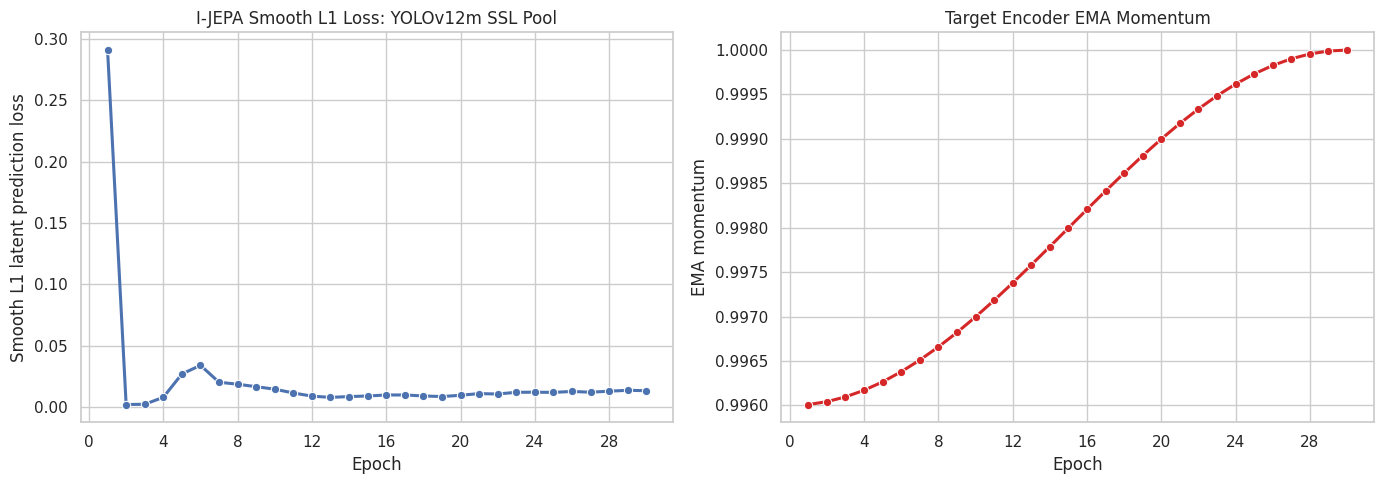

best SSL loss                                                              0.002087
best SSL checkpoint               /kaggle/working/partB_03a_ijepa_yolo12m/best_s...
latest resumable checkpoint       /kaggle/working/partB_03a_ijepa_yolo12m/last_s...
detector-compatible checkpoint    /kaggle/working/partB_03a_ijepa_yolo12m/ijepa_...
backbone key coverage                                                        100.0%
transfer report                   /kaggle/working/partB_03a_ijepa_yolo12m/ijepa_...
dtype: object

In [6]:
# ============================================================
# Loss curve, momentum schedule, and checkpoint handoff
# ============================================================
history = pd.read_csv(OUTPUT_DIR / "history.csv")
manifest = json.loads((OUTPUT_DIR / "run_manifest.json").read_text(encoding="utf-8"))
LAST_SSL_CHECKPOINT = Path(manifest["outputs"]["ssl_checkpoint"])
SSL_CHECKPOINT = OUTPUT_DIR / "best_ssl.pt"
assert SSL_CHECKPOINT.is_file(), f"Missing lowest-loss checkpoint: {SSL_CHECKPOINT}"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=history, x="epoch", y="loss", marker="o", linewidth=2.2, ax=axes[0])
axes[0].set(title="I-JEPA Smooth L1 Loss: YOLOv12m SSL Pool", xlabel="Epoch", ylabel="Smooth L1 latent prediction loss")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
sns.lineplot(data=history, x="epoch", y="ema_momentum", marker="o", linewidth=2.2, color="#d62728", ax=axes[1])
axes[1].set(title="Target Encoder EMA Momentum", xlabel="Epoch", ylabel="EMA momentum")
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "ijepa_loss_and_momentum.png", dpi=160); plt.show()

TRANSFERRED_YOLO = OUTPUT_DIR / "ijepa_best_backbone_yolo12m.pt"
transfer = transfer_ssl_backbone_to_yolo(
    SSL_CHECKPOINT, TRANSFERRED_YOLO, yolo_model=YOLO_MODEL, minimum_coverage=0.95,
)
pd.Series({
    "best SSL loss": manifest["best_loss"], "best SSL checkpoint": str(SSL_CHECKPOINT),
    "latest resumable checkpoint": str(LAST_SSL_CHECKPOINT),
    "detector-compatible checkpoint": str(TRANSFERRED_YOLO),
    "backbone key coverage": f"{transfer.coverage:.1%}", "transfer report": str(transfer.report_json),
})

## Representation Diagnostics And Retrieval Sanity Check

These diagnostics use a fixed, image-only sample from `ssl_pool/images`, not validation or test data. t-SNE preserves local neighborhoods only and is exploratory. The retrieval panel is the qualitative sanity check: a query should retrieve images with related pest appearance, scene structure, colour, or background rather than arbitrary images.

I-JEPA is designed to produce features that encode spatial structure. The diagnostics should show whether the features organize images by visual scene composition (leaf texture, background type, pest morphology) even without explicit class labels. Detection usefulness is established later by the downstream 20%-label experiment.

In [7]:
diagnostic_paths = sorted(random.Random(SEED).sample(ssl_paths, min(DIAGNOSTIC_IMAGES, len(ssl_paths))))
evaluation_transform = v2.Compose([
    v2.Resize(IMAGE_SIZE + 32, antialias=True), v2.CenterCrop(IMAGE_SIZE), v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True), v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
class SSLFeatureDataset(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            return evaluation_transform(image.convert("RGB")), self.paths[index].name

feature_loader = DataLoader(SSLFeatureDataset(diagnostic_paths), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
device = torch.device("cuda:0")  # Diagnostics are single-process inference after DDP training has exited.
diagnostic_detector = YOLO(str(TRANSFERRED_YOLO))
diagnostic_encoder = YOLOBackboneEncoder(diagnostic_detector.model).to(device).eval()
features, names = [], []
with torch.inference_mode():
    for images, batch_names in tqdm(feature_loader, desc="Extracting SSL-pool features"):
        features.append(F.normalize(diagnostic_encoder(images.to(device, non_blocking=True)), dim=1).cpu())
        names.extend(batch_names)
feature_matrix = torch.cat(features)
assert torch.isfinite(feature_matrix).all()
pd.Series({
    "diagnostic images": len(names), "feature dimensions": feature_matrix.shape[1],
    "mean L2 norm": feature_matrix.norm(dim=1).mean().item(),
    "mean feature std": feature_matrix.std(dim=0).mean().item(),
})

Extracting SSL-pool features:   0%|          | 0/8 [00:00<?, ?it/s]

diagnostic images     500.000000
feature dimensions    512.000000
mean L2 norm            1.000000
mean feature std        0.000059
dtype: float64

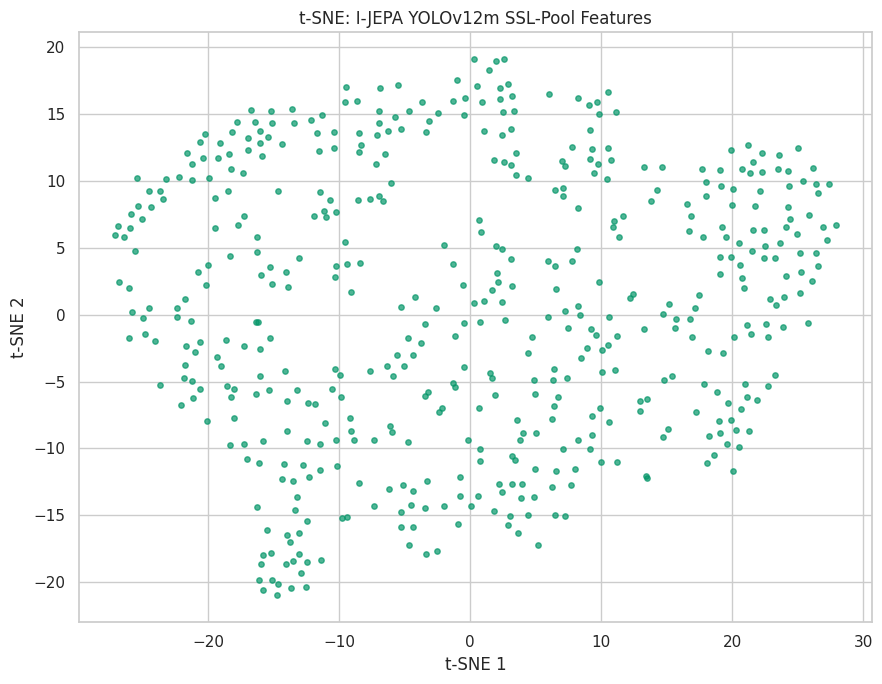

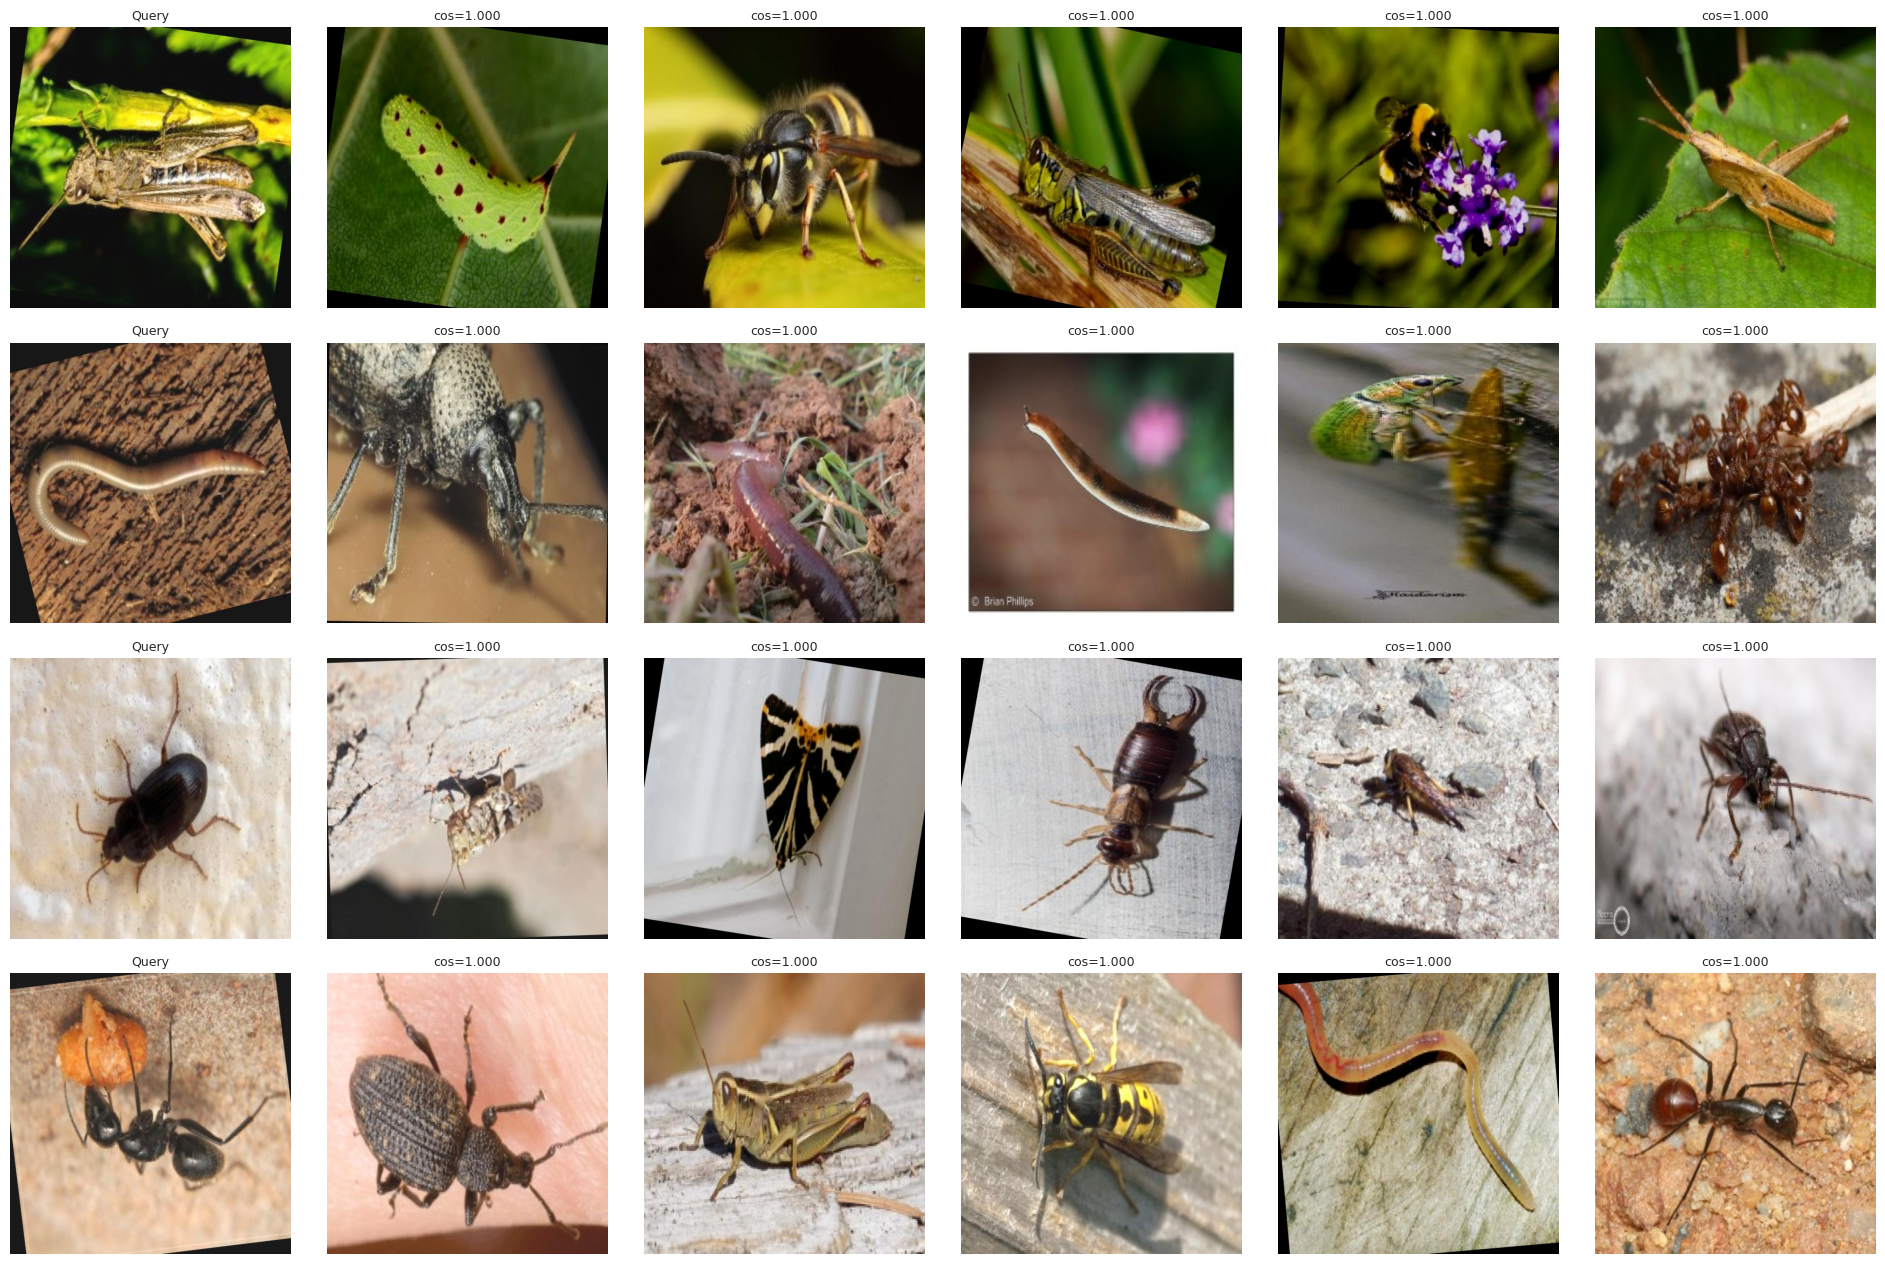

Interpretation to complete after execution: describe whether retrieved images share meaningful spatial-visual structure with the query, and defer all detection-performance claims to Notebook 03b.


In [8]:
perplexity = min(30.0, max(5.0, (len(feature_matrix) - 1) / 3))
coordinates = TSNE(n_components=2, perplexity=perplexity, learning_rate="auto", init="pca", max_iter=1000, random_state=SEED).fit_transform(feature_matrix.numpy())
fig, axis = plt.subplots(figsize=(9, 7))
axis.scatter(coordinates[:, 0], coordinates[:, 1], s=15, alpha=0.7, color="#059669")
axis.set(title="t-SNE: I-JEPA YOLOv12m SSL-Pool Features", xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "ijepa_tsne_ssl_pool.png", dpi=160); plt.show()
pd.DataFrame({"filename": names, "tsne_1": coordinates[:, 0], "tsne_2": coordinates[:, 1]}).to_csv(OUTPUT_DIR / "ssl_pool_embeddings_tsne.csv", index=False)

query_indices = random.Random(SEED).sample(range(len(diagnostic_paths)), RETRIEVAL_QUERIES)
fig, axes = plt.subplots(RETRIEVAL_QUERIES, RETRIEVAL_NEIGHBORS + 1, figsize=(3.2 * (RETRIEVAL_NEIGHBORS + 1), 3.2 * RETRIEVAL_QUERIES))
retrieval_rows = []
for row, query_index in enumerate(query_indices):
    similarities = feature_matrix @ feature_matrix[query_index]
    neighbor_indices = [index for index in torch.topk(similarities, k=RETRIEVAL_NEIGHBORS + 1).indices.tolist() if index != query_index][:RETRIEVAL_NEIGHBORS]
    display_indices = [query_index] + neighbor_indices
    for column, index in enumerate(display_indices):
        with Image.open(diagnostic_paths[index]) as image: axes[row, column].imshow(image.convert("RGB"))
        title = "Query" if column == 0 else f"cos={similarities[index]:.3f}"
        axes[row, column].set_title(title, fontsize=9); axes[row, column].axis("off")
        retrieval_rows.append({"query": diagnostic_paths[query_index].name, "rank": column, "match": diagnostic_paths[index].name, "cosine_similarity": float(similarities[index])})
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "ijepa_nearest_neighbors.png", dpi=160); plt.show()
pd.DataFrame(retrieval_rows).to_csv(OUTPUT_DIR / "ijepa_nearest_neighbors.csv", index=False)

print("Interpretation to complete after execution: describe whether retrieved images share meaningful spatial-visual structure with the query, and defer all detection-performance claims to Notebook 03b.")

## Checkpoint Publication And Viva Notes

Publish the complete `/kaggle/working/partB_03a_ijepa_yolo12m/` directory as a public Kaggle dataset. Notebook `03b` must attach it and use `best_ssl.pt` with its transfer report.

- **Context encoder:** online encoder that sees the image with target-block regions masked. Trained by gradient descent.
- **Target encoder:** identical architecture to online, sees the full unmasked image. Updated solely by EMA: \(\xi \leftarrow m\xi + (1-m)\theta\).
- **Transformer predictor:** maps context feature grid to target-block latents. Lightweight (depth 2, 4 heads). Discarded after pretraining.
- **Loss:** Smooth L1 between predicted latents and stop-gradient target latents. Prediction is in representation space, not pixel space — the model learns to predict semantic content, not reconstruct textures.
- **Why predict in latent space?** Pixel-space prediction (like MAE) spends capacity on high-frequency texture details irrelevant for detection. Latent-space prediction forces the context encoder to produce features that are informative about semantic regions.
- **Target blocks:** Randomly sampled rectangles on the spatial feature grid. Their union is masked from the context input. The predictor must infer these hidden regions from surrounding visible context.
- **No colour augmentations:** I-JEPA replaces hand-crafted colour jitter/grayscale/blur with the spatial masking objective. Spatial structure is a more transferable invariance for detection than colour constancy.
- **Integration route:** The online encoder's backbone weights are transferred directly into YOLOv12m (backbone replacement, not distillation). This is possible because I-JEPA uses the same YOLO CNN encoder for both context and target.
- **Viva Q&A:** Why I-JEPA avoids augmentations (masking replaces the invariance signal); how context/target blocks are sampled; why latent-space prediction beats pixel-space for detection semantics; how the ViT-free YOLO-native adaptation differs from the original ViT-H I-JEPA.